Muhammad Talha Ramzan
---
2330-0141
---
BS-AI
---
LAB 04
---
COMPUTER VISION


**Part 1 — Lab Activities**

**Cell 1: lab04_setup.py — Imports and Sample Binary Image**

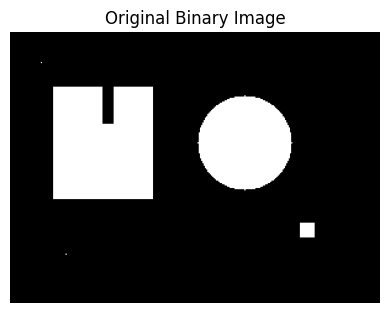

In [9]:

# Import OpenCV for image processing
import cv2

# Import NumPy for array operations
import numpy as np

# Import Matplotlib for displaying images
import matplotlib.pyplot as plt

# Import SciPy for binary morphology operations
from scipy import ndimage


# Define a function to display multiple images
def show_images(images, titles, figsize=None):
    if figsize is None:
        figsize = (4 * len(images), 4)

    plt.figure(figsize=figsize)

    for i, (img, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(1, len(images), i)
        plt.imshow(img, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Create a black binary image
binary = np.zeros((220, 300), dtype=np.uint8)

# Draw a white rectangle
cv2.rectangle(binary, (35, 45), (115, 135), 255, -1)

# Draw a white circle
cv2.circle(binary, (190, 90), 38, 255, -1)

# Draw a small white component
cv2.rectangle(binary, (235, 155), (246, 166), 255, -1)

# Create a small notch inside the rectangle
binary[45:75, 75:84] = 0

# Add isolated white noise pixels
binary[25, 25] = 255
binary[180, 45] = 255

# Display the original binary image
show_images([binary], ["Original Binary Image"])


**Activity 1 — Erosion**

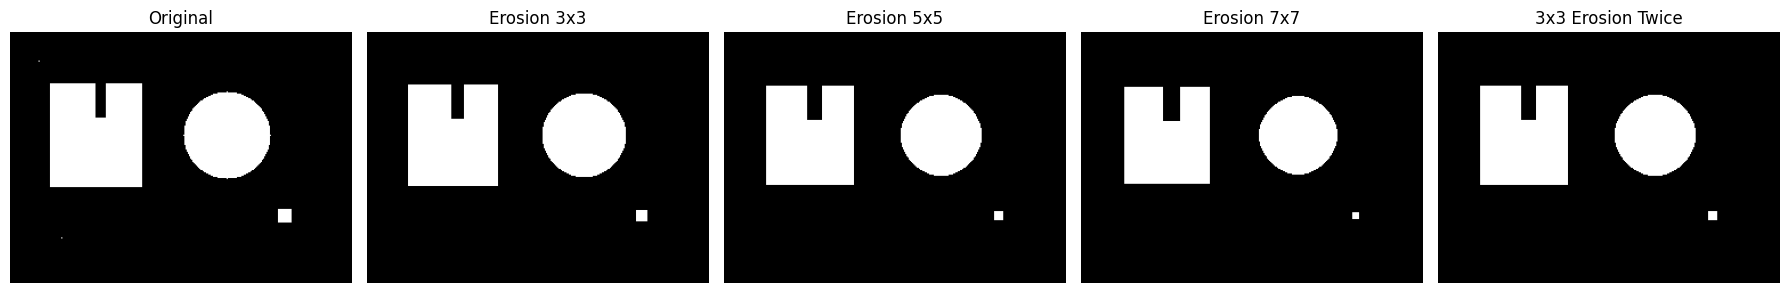

In [10]:

# Create square structuring elements
k3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
k5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
k7 = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))

# Apply erosion with different kernel sizes
eroded3 = cv2.erode(binary, k3, iterations=1)
eroded5 = cv2.erode(binary, k5, iterations=1)
eroded7 = cv2.erode(binary, k7, iterations=1)

# Apply erosion twice using a 3x3 kernel
eroded_twice = cv2.erode(binary, k3, iterations=2)

# Display the comparison
show_images(
    [binary, eroded3, eroded5, eroded7, eroded_twice],
    ["Original", "Erosion 3x3", "Erosion 5x5",
     "Erosion 7x7", "3x3 Erosion Twice"],
    figsize=(18, 4)
)


**Activity 2 — Dilation**

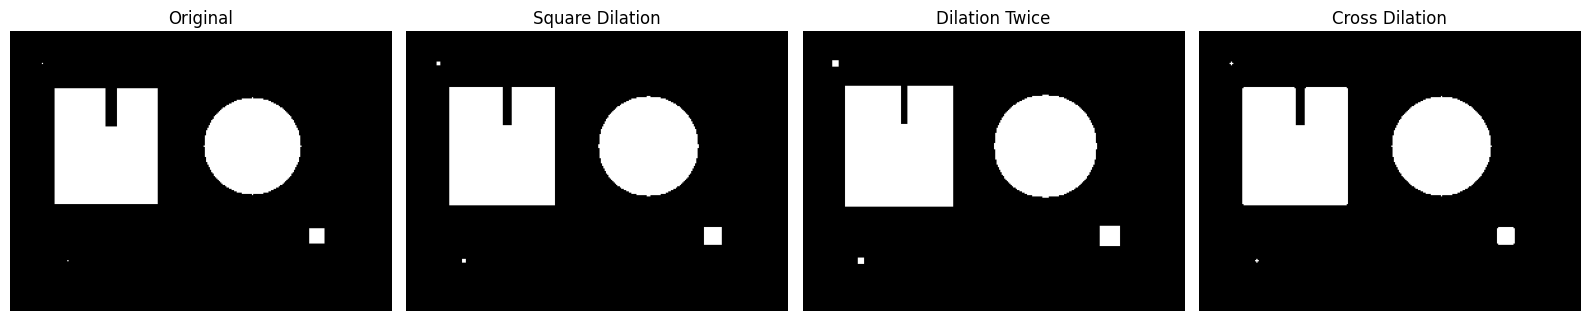

In [11]:

# Create a cross-shaped structuring element
cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))

# Apply square-shaped dilation once
dilated3 = cv2.dilate(binary, k3, iterations=1)

# Apply square-shaped dilation twice
dilated_twice = cv2.dilate(binary, k3, iterations=2)

# Apply cross-shaped dilation
dilated_cross = cv2.dilate(binary, cross, iterations=1)

# Display the results
show_images(
    [binary, dilated3, dilated_twice, dilated_cross],
    ["Original", "Square Dilation", "Dilation Twice", "Cross Dilation"]
)


**Activity 3 — Morphological Duality**

Complement erosion equals dilation complement: True
Complement dilation equals erosion complement: False


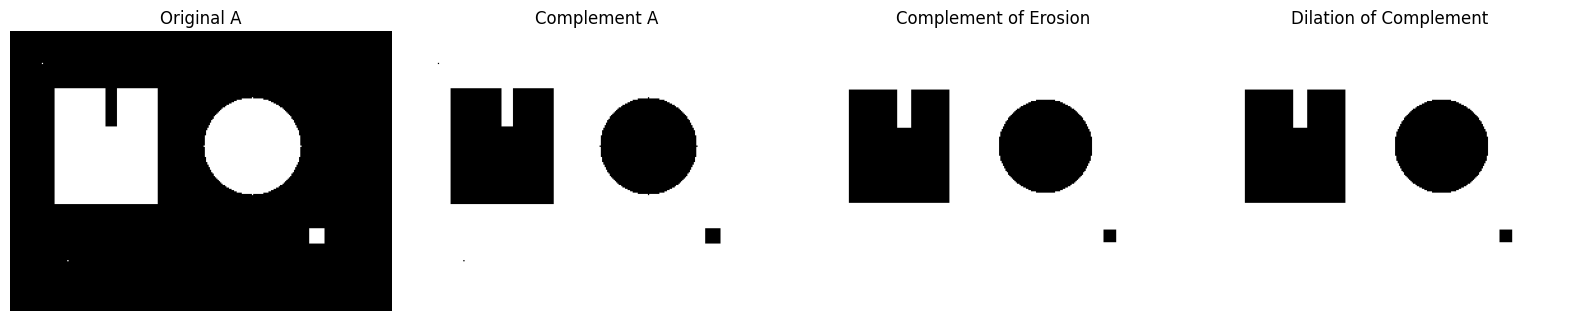

In [12]:

# Convert the image into a Boolean binary array
A = binary > 0

# Create a symmetric square structuring element
B = np.ones((3, 3), dtype=bool)

# Calculate the complement of erosion
lhs1 = ~ndimage.binary_erosion(A, structure=B, border_value=0)

# Calculate dilation of the complement
rhs1 = ndimage.binary_dilation(~A, structure=B, border_value=0)

# Calculate the complement of dilation
lhs2 = ~ndimage.binary_dilation(A, structure=B, border_value=0)

# Calculate erosion of the complement
rhs2 = ndimage.binary_erosion(~A, structure=B, border_value=0)

# Check both duality relationships
print("Complement erosion equals dilation complement:",
      np.array_equal(lhs1, rhs1))

print("Complement dilation equals erosion complement:",
      np.array_equal(lhs2, rhs2))

# Display the images
show_images(
    [A.astype(np.uint8) * 255,
     (~A).astype(np.uint8) * 255,
     lhs1.astype(np.uint8) * 255,
     rhs1.astype(np.uint8) * 255],
    ["Original A", "Complement A",
     "Complement of Erosion", "Dilation of Complement"]
)


Lab Activity: Cross-shaped SE ke saath repeat

In [13]:
B = np.array([
    [False, True, False],
    [True,  True, True],
    [False, True, False]
], dtype=bool)

**Activity 4 — Opening**

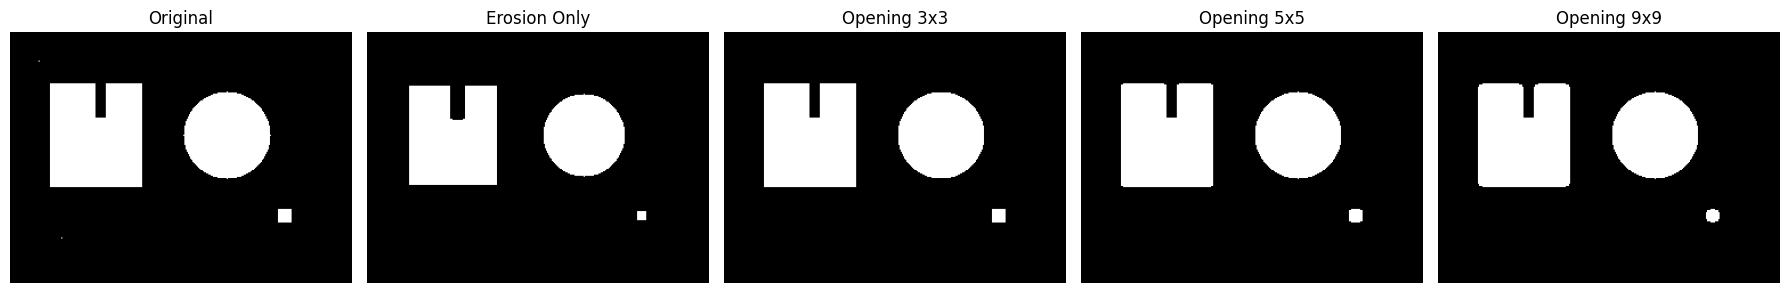

In [14]:

# Create square and elliptical structuring elements
open3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
open5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
open9 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))

# Apply opening with different kernel sizes
opened3 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, open3)
opened5 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, open5)
opened9 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, open9)

# Apply erosion alone for comparison
erosion_only = cv2.erode(binary, open5, iterations=1)

# Display all results
show_images(
    [binary, erosion_only, opened3, opened5, opened9],
    ["Original", "Erosion Only", "Opening 3x3",
     "Opening 5x5", "Opening 9x9"],
    figsize=(18, 4)
)


**Activity 5 — Closing**

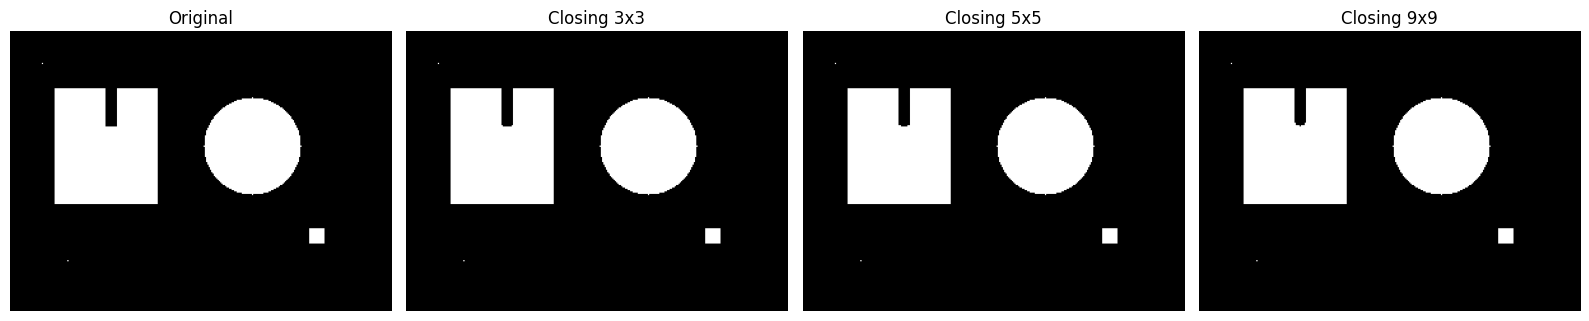

In [15]:

# Create elliptical structuring elements
close3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
close5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
close9 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))

# Apply closing with different kernel sizes
closed3 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, close3)
closed5 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, close5)
closed9 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, close9)

# Display the results
show_images(
    [binary, closed3, closed5, closed9],
    ["Original", "Closing 3x3", "Closing 5x5", "Closing 9x9"],
    figsize=(16, 4)
)


**Activity 6 — Hit-or-Miss Transform**

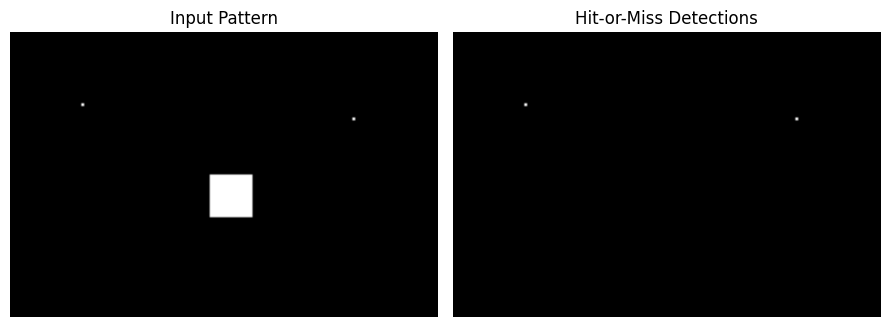

Match coordinates (row, col): [[ 25  25]
 [ 30 120]]


In [16]:

# Create a binary image for pattern detection
pattern_img = np.zeros((100, 150), dtype=np.uint8)

# Add two isolated foreground pixels
pattern_img[25, 25] = 255
pattern_img[30, 120] = 255

# Add a larger white block
pattern_img[50:65, 70:85] = 255

# Convert the image into binary values 0 and 1
src = (pattern_img > 0).astype(np.uint8)

# Define the isolated-pixel detection kernel
hitmiss_kernel = np.array([
    [-1, -1, -1],
    [-1,  1, -1],
    [-1, -1, -1]
], dtype=np.int8)

# Detect the required foreground-background pattern
hits = cv2.morphologyEx(
    src, cv2.MORPH_HITMISS, hitmiss_kernel
)

# Display the input and detected patterns
show_images(
    [src * 255, hits * 255],
    ["Input Pattern", "Hit-or-Miss Detections"],
    figsize=(9, 4)
)

# Print the matching pixel coordinates
print("Match coordinates (row, col):", np.argwhere(hits > 0))


**Activity 7 — Boundary Extraction**

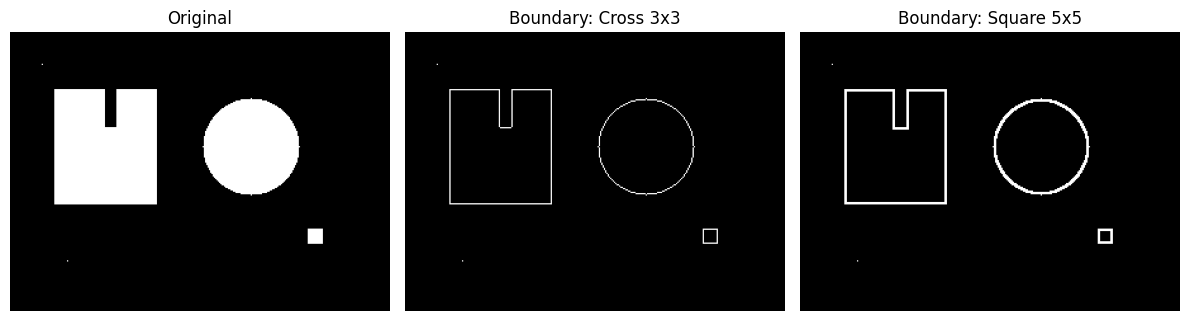

In [17]:

# Convert the image into an 8-bit binary image
A8 = (binary > 0).astype(np.uint8) * 255

# Create a 3x3 cross-shaped structuring element
cross3 = cv2.getStructuringElement(
    cv2.MORPH_CROSS, (3, 3)
)

# Create a 5x5 square structuring element
square5 = cv2.getStructuringElement(
    cv2.MORPH_RECT, (5, 5)
)

# Erode using the cross-shaped kernel
eroded_cross = cv2.erode(A8, cross3, iterations=1)

# Erode using the square-shaped kernel
eroded_square = cv2.erode(A8, square5, iterations=1)

# Extract the internal boundaries
boundary_cross = cv2.subtract(A8, eroded_cross)
boundary_square = cv2.subtract(A8, eroded_square)

# Display the boundary comparison
show_images(
    [A8, boundary_cross, boundary_square],
    ["Original", "Boundary: Cross 3x3", "Boundary: Square 5x5"]
)


**Activity 8 — Hole Filling**

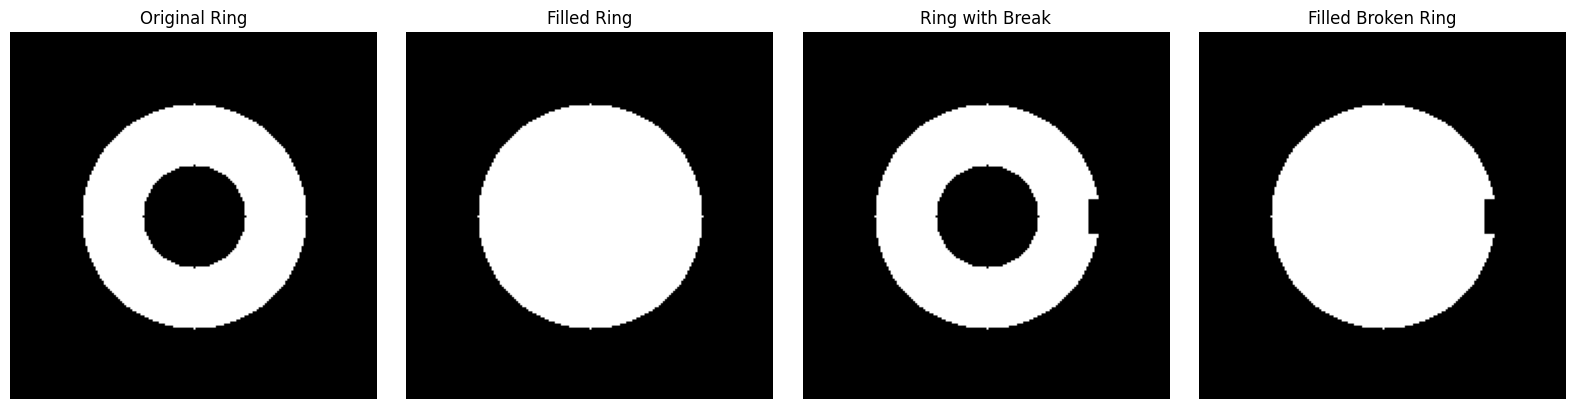

In [18]:

# Create a black image
ring = np.zeros((180, 180), dtype=np.uint8)

# Draw a filled white circle
cv2.circle(ring, (90, 90), 55, 255, -1)

# Create a black hole inside the circle
cv2.circle(ring, (90, 90), 25, 0, -1)

# Fill enclosed holes in the binary image
filled = ndimage.binary_fill_holes(
    ring > 0
).astype(np.uint8) * 255

# Create another ring with a break
broken_ring = ring.copy()
broken_ring[82:99, 140:155] = 0

# Fill holes in the broken ring
filled_broken = ndimage.binary_fill_holes(
    broken_ring > 0
).astype(np.uint8) * 255

# Display both examples
show_images(
    [ring, filled, broken_ring, filled_broken],
    ["Original Ring", "Filled Ring",
     "Ring with Break", "Filled Broken Ring"],
    figsize=(16, 4)
)


**Part 2 — Lab Tasks (Assessed Tasks)**

Lab Task 1 — Compare Square, Cross and Ellipse SEs

Square Structuring Element:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
Cross Structuring Element:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
Ellipse Structuring Element:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


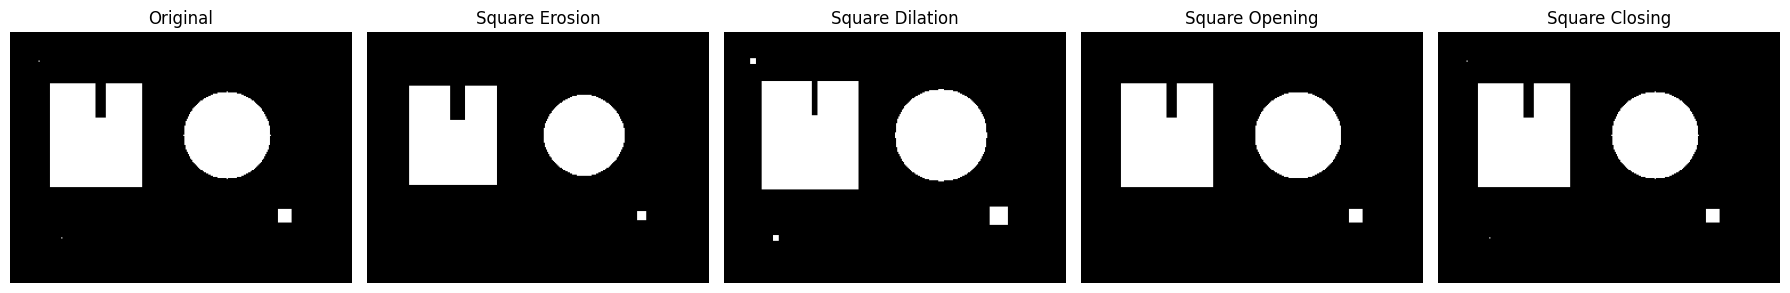

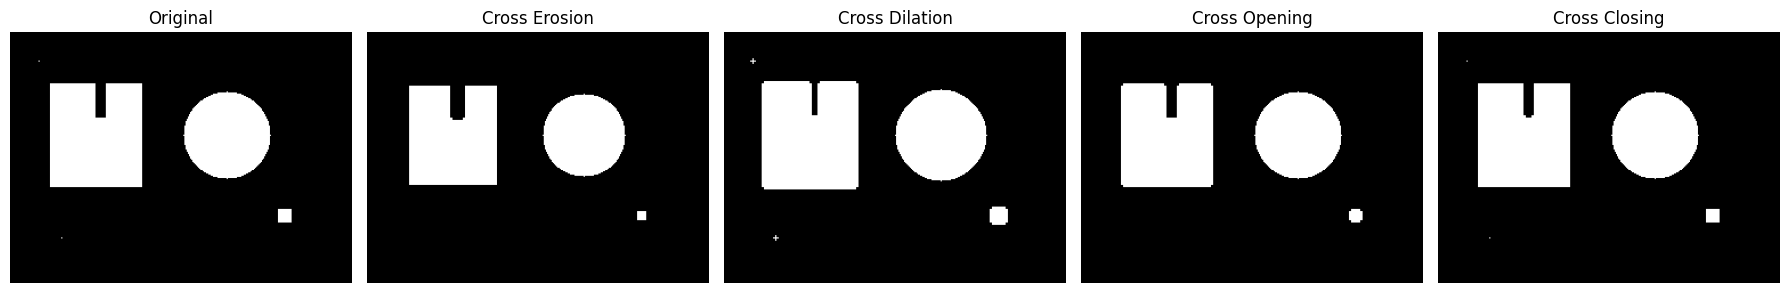

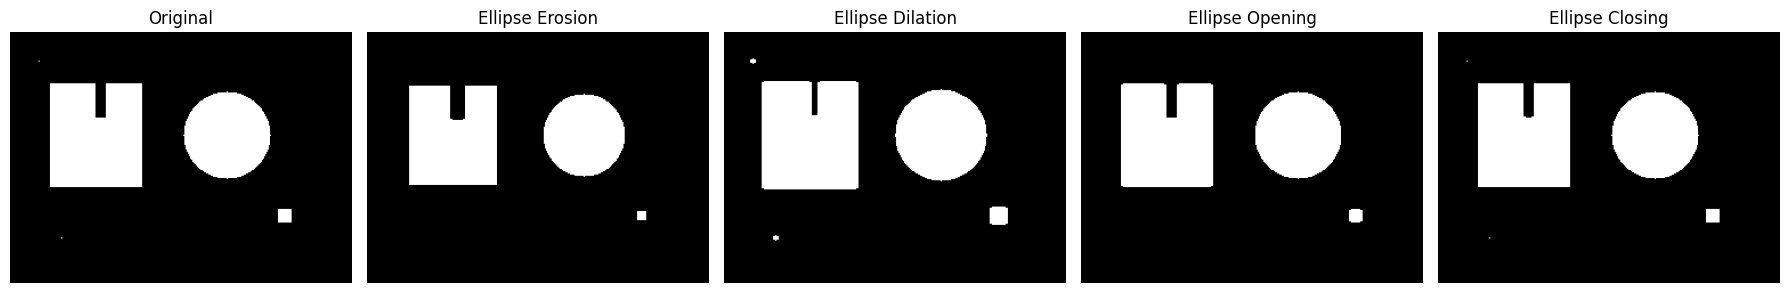

In [19]:

# Create three structuring elements of size 5x5
square = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))
ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

# Store the kernels with their names
kernels = [
    ("Square", square),
    ("Cross", cross),
    ("Ellipse", ellipse)
]

# Display each structuring element
for name, kernel in kernels:
    print(name, "Structuring Element:")
    print(kernel)

# Apply all four operations to each structuring element
for name, kernel in kernels:
    eroded = cv2.erode(binary, kernel, iterations=1)
    dilated = cv2.dilate(binary, kernel, iterations=1)
    opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    # Display the original and processed images
    show_images(
        [binary, eroded, dilated, opened, closed],
        ["Original", name + " Erosion", name + " Dilation",
         name + " Opening", name + " Closing"],
        figsize=(18, 4)
    )


**Lab Task 2 — Remove Isolated Foreground Noise**

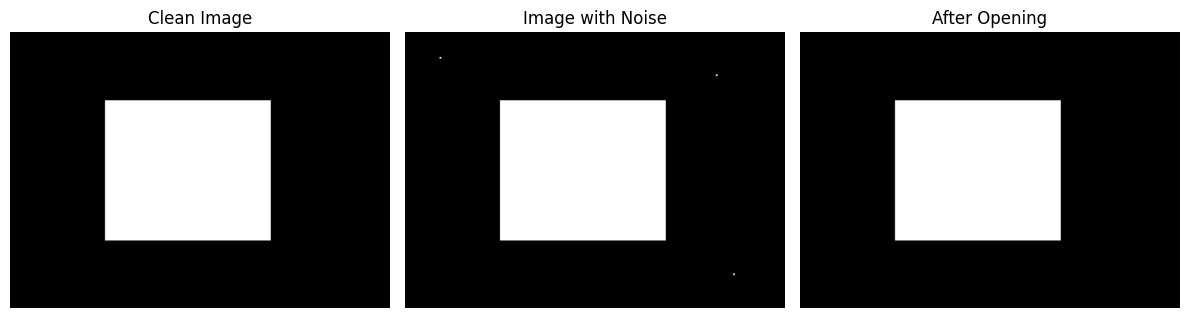

Foreground pixels before: 7779
Foreground pixels after: 7776


In [20]:

# Create a clean black binary image
clean = np.zeros((160, 220), dtype=np.uint8)

# Draw a large foreground object
cv2.rectangle(clean, (55, 40), (150, 120), 255, -1)

# Add three isolated noise pixels
noisy = clean.copy()
noisy[15, 20] = 255
noisy[25, 180] = 255
noisy[140, 190] = 255

# Create a 3x3 square structuring element
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

# Remove small foreground components using opening
denoised = cv2.morphologyEx(
    noisy, cv2.MORPH_OPEN, kernel
)

# Display the results
show_images(
    [clean, noisy, denoised],
    ["Clean Image", "Image with Noise", "After Opening"]
)

# Count foreground pixels before and after processing
print("Foreground pixels before:", np.count_nonzero(noisy))
print("Foreground pixels after:", np.count_nonzero(denoised))


**Lab Task 3 — Connect Two Objects Using Closing**

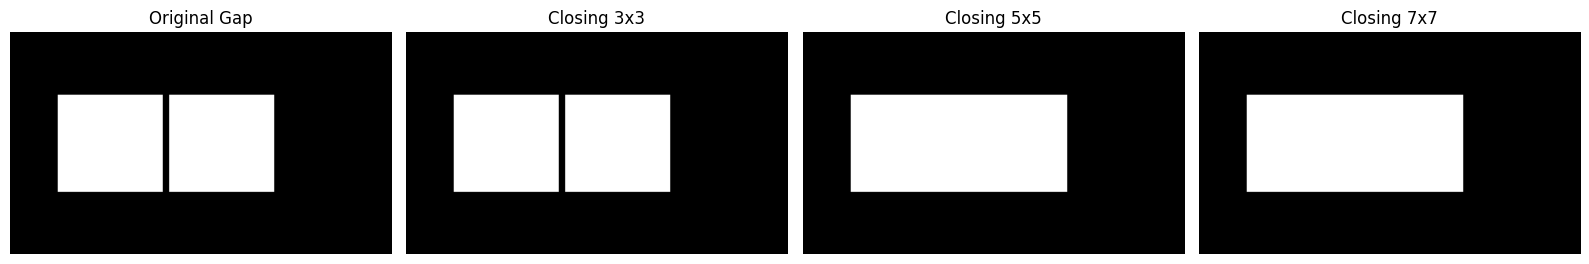

3x3 foreground components: 2
5x5 foreground components: 1
7x7 foreground components: 1


In [21]:

# Create a black binary image
gap_image = np.zeros((140, 240), dtype=np.uint8)

# Draw the first white rectangle
cv2.rectangle(gap_image, (30, 40), (95, 100), 255, -1)

# Draw the second white rectangle with a narrow gap
cv2.rectangle(gap_image, (100, 40), (165, 100), 255, -1)

# Create different closing kernels
close3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
close5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
close7 = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))

# Apply closing with different kernel sizes
result3 = cv2.morphologyEx(
    gap_image, cv2.MORPH_CLOSE, close3
)
result5 = cv2.morphologyEx(
    gap_image, cv2.MORPH_CLOSE, close5
)
result7 = cv2.morphologyEx(
    gap_image, cv2.MORPH_CLOSE, close7
)

# Display the comparison
show_images(
    [gap_image, result3, result5, result7],
    ["Original Gap", "Closing 3x3", "Closing 5x5", "Closing 7x7"],
    figsize=(16, 4)
)

# Check whether the two objects are connected
for name, result in [
    ("3x3", result3),
    ("5x5", result5),
    ("7x7", result7)
]:
    count, labels, stats, centroids = cv2.connectedComponentsWithStats(
        (result > 0).astype(np.uint8), connectivity=8
    )
    print(name, "foreground components:", count - 1)


**Lab Task 4 — Hit-or-Miss for Endpoint Detection**

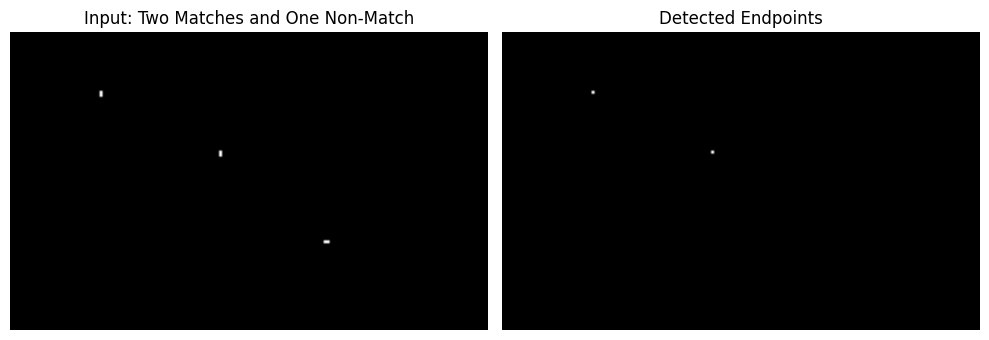

Detected coordinates (row, col):
[[20 30]
 [40 70]]
Total matches: 2


In [22]:

# Create a black binary image
endpoint_image = np.zeros((100, 160), dtype=np.uint8)

# Create the first vertical two-pixel line
endpoint_image[20, 30] = 255
endpoint_image[21, 30] = 255

# Create the second vertical two-pixel line
endpoint_image[40, 70] = 255
endpoint_image[41, 70] = 255

# Create a horizontal line as a non-matching pattern
endpoint_image[70, 105] = 255
endpoint_image[70, 106] = 255

# Convert the image to binary values 0 and 1
src = (endpoint_image > 0).astype(np.uint8)

# Design a kernel for an endpoint with a foreground pixel below
endpoint_kernel = np.array([
    [-1, -1, -1],
    [-1,  1, -1],
    [ 0,  1,  0]
], dtype=np.int8)

# Detect matching endpoint patterns
matches = cv2.morphologyEx(
    src, cv2.MORPH_HITMISS, endpoint_kernel
)

# Display the input and detection results
show_images(
    [src * 255, matches * 255],
    ["Input: Two Matches and One Non-Match",
     "Detected Endpoints"],
    figsize=(10, 4)
)

# Print detected coordinates
coordinates = np.argwhere(matches > 0)
print("Detected coordinates (row, col):")
print(coordinates)

# Print the number of detections
print("Total matches:", len(coordinates))


**Lab Task 5 — Hole Filling and External Notch**

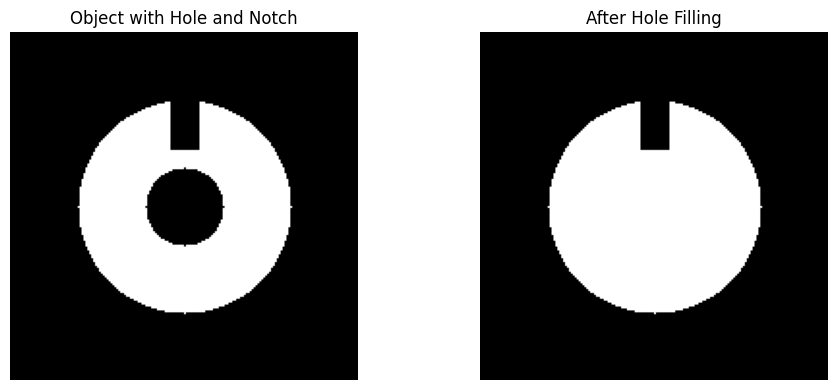

Center pixel before filling: 0
Center pixel after filling: 255
Notch pixel before filling: 0
Notch pixel after filling: 0


In [23]:

# Create a black binary image
object_image = np.zeros((180, 180), dtype=np.uint8)

# Draw a filled white circular object
cv2.circle(object_image, (90, 90), 55, 255, -1)

# Create an enclosed black hole inside the object
cv2.circle(object_image, (90, 90), 20, 0, -1)

# Create an external notch from the top boundary
object_image[30:61, 83:98] = 0

# Fill enclosed holes
filled_object = ndimage.binary_fill_holes(
    object_image > 0
).astype(np.uint8) * 255

# Display the original and filled results
show_images(
    [object_image, filled_object],
    ["Object with Hole and Notch", "After Hole Filling"],
    figsize=(10, 4)
)

# Check pixel values in the enclosed hole
print("Center pixel before filling:", object_image[90, 90])
print("Center pixel after filling:", filled_object[90, 90])

# Check a pixel inside the external notch
print("Notch pixel before filling:", object_image[40, 90])
print("Notch pixel after filling:", filled_object[40, 90])


Final Erosion Matrix:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


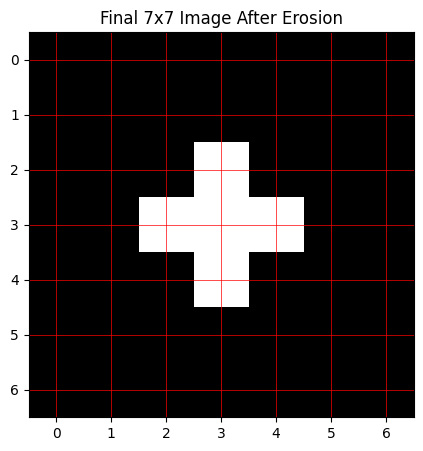

In [27]:

# Import NumPy for creating and processing matrices
import numpy as np

# Import Matplotlib for visualization
import matplotlib.pyplot as plt

# Import Rectangle for highlighting the moving kernel
from matplotlib.patches import Rectangle

# Import display tools for showing animation frames
from IPython.display import display, clear_output
import time

# Create the original 7x7 binary image
image = np.array([
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 1, 0, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 0, 1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)

# Create a 3x3 kernel containing only ones
kernel = np.ones((3, 3), dtype=np.uint8)

# Add a black border around the image
padded = np.pad(image, 1, mode="constant", constant_values=0)

# Create an empty 7x7 output matrix
output = np.zeros_like(image)

# Visit each pixel row by row
for r in range(7):
    for c in range(7):

        # Select the 3x3 region under the kernel
        region = padded[r:r+3, c:c+3]

        # Apply the erosion rule manually
        output[r, c] = 1 if np.all(region == 1) else 0

        # Clear the previous frame
        clear_output(wait=True)

        # Create three visualization panels
        fig, axes = plt.subplots(1, 3, figsize=(12, 4))

        # Show the original 7x7 image
        axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[0].set_title("Original 7x7 Image")

        # Highlight the current 3x3 kernel position
        axes[0].add_patch(
            Rectangle(
                (c - 1.5, r - 1.5), 3, 3,
                fill=False, edgecolor="red", linewidth=2
            )
        )

        # Show the current 3x3 neighborhood
        axes[1].imshow(region, cmap="gray", vmin=0, vmax=1)
        axes[1].set_title("Current 3x3 Neighborhood")

        # Show the output matrix built so far
        axes[2].imshow(output, cmap="gray", vmin=0, vmax=1)
        axes[2].set_title("Erosion Output")

        # Add grid lines to all panels
        for ax in axes:
            ax.set_xticks(np.arange(-0.5, 7, 1))
            ax.set_yticks(np.arange(-0.5, 7, 1))
            ax.grid(color="red", linewidth=0.5)
            ax.set_xticklabels([])
            ax.set_yticklabels([])

        # Explain the current pixel decision
        if np.all(region == 1):
            decision = "All 9 pixels are 1 -> output 1"
        else:
            decision = "At least one pixel is 0 -> output 0"

        fig.suptitle(
            f"Checking row {r}, column {c}\n{decision}"
        )

        # Display the current animation frame
        plt.tight_layout()
        display(fig)
        plt.close(fig)

        # Pause briefly so the movement is visible
        time.sleep(0.3)

# Display the final eroded matrix
clear_output(wait=True)

print("Final Erosion Matrix:")
print(output)

plt.figure(figsize=(5, 5))
plt.imshow(output, cmap="gray", vmin=0, vmax=1)
plt.title("Final 7x7 Image After Erosion")
plt.xticks(range(7))
plt.yticks(range(7))
plt.grid(color="red", linewidth=0.5)
plt.show()


Final Dilation Matrix:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


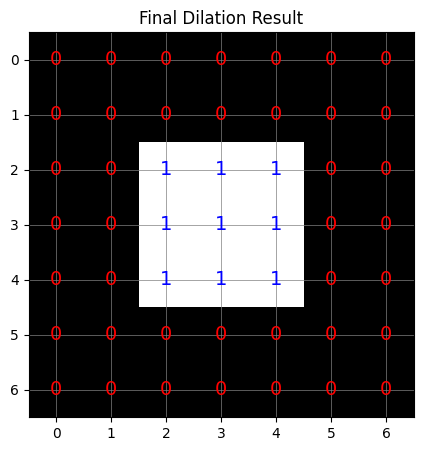

In [30]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, clear_output
import time

# Create a 7x7 binary image filled with zeros
image = np.zeros((7, 7), dtype=np.uint8)

# Put one white pixel in the center
image[3, 3] = 1

# Create an empty output image
output = np.zeros_like(image)

# Define the 3x3 kernel
kernel = np.ones((3, 3), dtype=np.uint8)

# Move the kernel over the image
for r in range(1, 6):
    for c in range(1, 6):

        # Select the 3x3 area under the kernel
        area = image[r-1:r+2, c-1:c+2]

        # If any pixel is 1, make the center output pixel 1
        if np.any(area == 1):
            output[r, c] = 1

        # Clear the previous animation frame
        clear_output(wait=True)

        # Create two side-by-side views
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        # Show the original image
        axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)

        # Draw the moving kernel
        axes[0].add_patch(Rectangle(
            (c-1.5, r-1.5), 3, 3,
            fill=False, edgecolor="red", linewidth=2
        ))

        # Write 0 and 1 inside every original pixel
        for i in range(7):
            for j in range(7):
                axes[0].text(j, i, str(image[i, j]),
                             ha="center", va="center",
                             color="red" if image[i, j] == 0 else "blue",
                             fontsize=12)

        axes[0].set_title(f"Original + Kernel (center: {r},{c})")
        axes[0].set_xticks(range(7))
        axes[0].set_yticks(range(7))
        axes[0].grid(True, color="gray", linewidth=0.5)

        # Show the output image so far
        axes[1].imshow(output, cmap="gray", vmin=0, vmax=1)

        # Write 0 and 1 inside every output pixel
        for i in range(7):
            for j in range(7):
                axes[1].text(j, i, str(output[i, j]),
                             ha="center", va="center",
                             color="red" if output[i, j] == 0 else "blue",
                             fontsize=12)

        axes[1].set_title("Dilation Output")
        axes[1].set_xticks(range(7))
        axes[1].set_yticks(range(7))
        axes[1].grid(True, color="gray", linewidth=0.5)

        plt.tight_layout()
        display(fig)
        plt.close(fig)
        time.sleep(0.3)

# Display the final result
clear_output(wait=True)

print("Final Dilation Matrix:")
print(output)

plt.figure(figsize=(5, 5))
plt.imshow(output, cmap="gray", vmin=0, vmax=1)

for i in range(7):
    for j in range(7):
        plt.text(j, i, str(output[i, j]),
                 ha="center", va="center",
                 color="red" if output[i, j] == 0 else "blue",
                 fontsize=14)

plt.title("Final Dilation Result")
plt.xticks(range(7))
plt.yticks(range(7))
plt.grid(True, color="gray", linewidth=0.5)
plt.show()


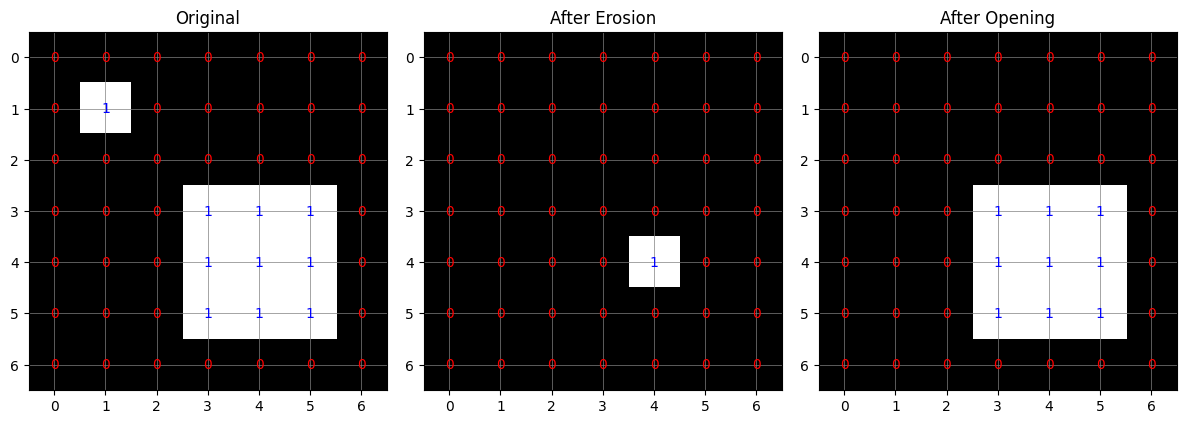

Opening Result:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 1 1 0]
 [0 0 0 1 1 1 0]
 [0 0 0 1 1 1 0]
 [0 0 0 0 0 0 0]]


In [31]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a 7x7 black binary image
image = np.zeros((7, 7), dtype=np.uint8)

# Add one isolated white noise pixel
image[1, 1] = 1

# Add a 3x3 white main object
image[3:6, 3:6] = 1

# Create a 3x3 kernel
kernel = np.ones((3, 3), dtype=np.uint8)

# Apply erosion first
eroded = cv2.erode(image, kernel, iterations=1)

# Apply dilation to the eroded image
opened = cv2.dilate(eroded, kernel, iterations=1)

# Display original, eroded, and opened images
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

images = [image, eroded, opened]
titles = ["Original", "After Erosion", "After Opening"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(7))
    ax.set_yticks(range(7))
    ax.grid(True, color="gray", linewidth=0.5)

    # Display 0 and 1 in every pixel
    for r in range(7):
        for c in range(7):
            ax.text(c, r, str(img[r, c]),
                    ha="center", va="center",
                    color="red" if img[r, c] == 0 else "blue")

plt.tight_layout()
plt.show()

# Print the final opening matrix
print("Opening Result:")
print(opened)


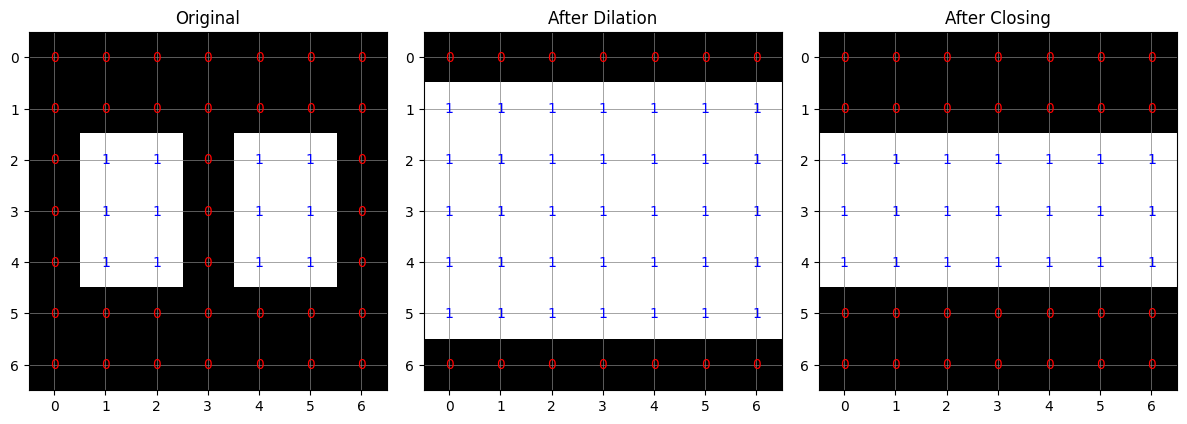

Closing Result:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


In [32]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a 7x7 binary image
image = np.zeros((7, 7), dtype=np.uint8)

# Create a white object with a small black gap
image[2:5, 1:3] = 1
image[2:5, 3:4] = 0
image[2:5, 4:6] = 1

# Create a 3x3 kernel
kernel = np.ones((3, 3), dtype=np.uint8)

# Step 1: Apply dilation
dilated = cv2.dilate(image, kernel, iterations=1)

# Step 2: Apply erosion
closed = cv2.erode(dilated, kernel, iterations=1)

# Display original, dilated, and closed images
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

images = [image, dilated, closed]
titles = ["Original", "After Dilation", "After Closing"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(7))
    ax.set_yticks(range(7))
    ax.grid(True, color="gray", linewidth=0.5)

    # Write 0 and 1 inside every pixel
    for r in range(7):
        for c in range(7):
            ax.text(c, r, str(img[r, c]),
                    ha="center", va="center",
                    color="red" if img[r, c] == 0 else "blue")

plt.tight_layout()
plt.show()

# Print the final matrix
print("Closing Result:")
print(closed)


In [33]:
import numpy as np

# Create a binary image
image = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 0, 0],
    [0, 0, 0, 0, 0]
], dtype=np.uint8)

# Find the complement of the image
complement = 1 - image

# Display the original image
print("Original Image:")
print(image)

# Display the complement image
print("Complement Image:")
print(complement)

Original Image:
[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 1 1 0 0]
 [0 0 0 0 0]]
Complement Image:
[[1 1 1 1 1]
 [1 0 0 1 1]
 [1 0 0 0 1]
 [1 0 0 1 1]
 [1 1 1 1 1]]
